# Example of an interface usage - Dispersion Measurement

As mentioned in a previous tutorial, interface allows its users to quickly and in an easy way interact with the machine. The possibilities are countless, one of them is for example very simple example on how to measure dispersion.

Dispersion $D$ tells how much the orbit moves when the beam energy changes by a relative amount $\delta$: $\Delta x=D\,\delta$. To measure it, read the orbit at the nominal energy, change the energy, read the orbit again and divide the difference by $\delta$.

The example uses the tutorial beamline. With a real interface only the line that creates `interface` changes, e.g. `InterfaceCLEAR_RFTrack()` for the CLEAR simulation or `InterfaceCLEAR()` for the machine.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import Beamline

interface = Beamline(nsamples=50)
bpms = interface.get_bpms()["names"]

## Measure

Change the energy only inside `try` and reset it in `finally`, so that the beam returns to nominal even if a reading fails. `get_orbit` averages the `nsamples` shots of every BPM.

In [2]:
nominal = interface.get_state().get_orbit(bpms)
try:
    delta = interface.change_energy()
    changed = interface.get_state().get_orbit(bpms)
finally:
    interface.reset_energy()
print('Relative energy change δ =', round(delta, 3))

Relative energy change δ = -0.1


## Compute the dispersion

$$D=\frac{\bar x_E-\bar x_0}{\delta},\qquad u(D)=\frac{1}{|\delta|}\sqrt{\frac{s_0^2}{N}+\frac{s_E^2}{N}} .$$

What `change_energy()` returns depends on the interface: the tutorial beamline and the CLEAR RF-Track simulation return $\delta$, the real CLEAR interface returns the new RF phase, so there $\delta$ has to come from an energy measurement.

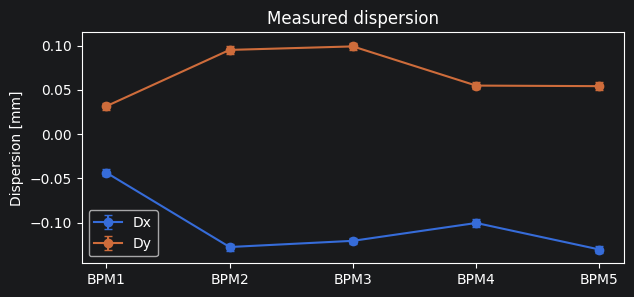

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
for plane in ('x', 'y'):
    D = (changed[plane] - nominal[plane]) / delta
    u = np.sqrt(nominal['std' + plane]**2 / nominal['nshots'] + changed['std' + plane]**2 / changed['nshots']) / abs(delta)
    ax.errorbar(nominal['names'], D, yerr=u, fmt='o-', capsize=3, label=f'D{plane}')
ax.set(ylabel='Dispersion [mm]', title='Measured dispersion')
ax.legend()
plt.show()

In this beamline all dispersion comes from corrector and error kicks: an off-energy beam is kicked less, so its orbit differs. This is the signal that dispersion-free steering minimizes, see [Beam-Based Alignment](04_BeamBasedAlignment.ipynb).